# 05. Hybrid Architecture & Ablation Analysis (H1, H2, and Controls)
**Contributor:** Ranajeet (Hybrid Owner)  
**Deliverable:** Phase 2 Deliverable N7 (`notebooks/05_hybrid_analysis.ipynb`)

## Executive Summary
This notebook conducts a rigorous, multi-faceted empirical evaluation of:
1. **Hybrid Model H1 (`mpnn+desc`)**: Concatenation of MPNN learned graph representations (Set2Set readout) with 213 standardized 2D RDKit molecular descriptors.
2. **Hybrid Model H2 (`ens_xgb_fpmlp+both`)**: Late-fusion rank-average ensemble of Phase 1 XGBoost (`morgan+desc`) and the best deep model. The deep partner is selected **on validation PR AUC only** (Section 0 below); that rule returns the FP-MLP control, not H1. The `xgb`+H1 pairing (`ens_xgb_mpnn+desc`) is retained as a documented secondary variant.
3. **Control 1: FP-MLP (`fpmlp+both`)**: Neural learner trained on identical features (Morgan + descriptors) to isolate the neural architecture effect from the graph representation.
4. **Control 2: Shuffled Descriptors (`shuffled_desc`)**: Negative control with identical parameters and feature distribution but permuted molecule assignments to test whether descriptor gains stem from true chemical context or model capacity.
5. **Control 3: Morgan Bit Substitution (`mpnn+morgan`, `mpnn+both`)**: Evaluating whether high-dimensional sparse topological bits aid or hinder graph message passing compared to low-dimensional continuous physicochemical descriptors.


In [1]:
import sys
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure project root is in path
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.config import RESULTS, ENDPOINTS, SEEDS
from src.dl import analysis as A

print(f"Results Directory: {RESULTS}")


Results Directory: /Users/ranajeetroy/Desktop/Molecular-Toxicity-Prediction/tox21-phase1/results


In [2]:
# Load all committed test results and ablations
df = A.load_all(RESULTS)
abl = A.load_ablations(RESULTS)

print("Unique models and feature sets loaded:")
print(df[["model", "feature_set", "tag"]].drop_duplicates().to_string(index=False))


Unique models and feature sets loaded:
             model            feature_set   tag
            logreg                 morgan final
            logreg            morgan+desc final
                rf                 morgan final
                rf            morgan+desc final
               xgb                 morgan final
               xgb            morgan+desc final
              mpnn                  graph final
               gcn                  graph final
        fpmlp+both                   both final
         mpnn+desc             graph+desc final
ens_xgb_fpmlp+both       morgan+desc+both final
 ens_xgb_mpnn+desc morgan+desc+graph+desc final


## 0. Selecting the H2 Deep Partner (Validation Only)

Protocol rule (handbook 4.3 / 8.6): the deep partner for the H2 rank-average must be chosen on
**validation** PR AUC, never on test. We read the per-epoch `val_pr` recorded in the committed
learning curves of the final runs and take each model's peak validation PR AUC, averaged over
seeds 0-2. No test prediction is touched by this cell.


In [3]:
curves_dir = RESULTS / "curves"

def peak_val_pr(model_fs: str, split: str = "scaffold", seeds=(0, 1, 2)) -> list[float]:
    """Peak validation PR AUC per seed, read from the committed final-run curves."""
    out = []
    for k in seeds:
        f = curves_dir / f"{model_fs}_{split}_seed{k}_final.json"
        if not f.exists():
            return []
        out.append(max(e["val_pr"] for e in json.loads(f.read_text())))
    return out

candidates = {
    "fpmlp+both": "fpmlp+both_both",
    "mpnn+desc (H1)": "mpnn+desc_graph+desc",
    "gcn": "gcn_graph",
    "mpnn": "mpnn_graph",
}

rows = []
for label, stem in candidates.items():
    vals = peak_val_pr(stem)
    if vals:
        rows.append({"model": label, "val_pr_mean": np.mean(vals), "val_pr_std": np.std(vals, ddof=1),
                     **{f"seed{i}": v for i, v in enumerate(vals)}})
    else:
        print(f"NOTE: curves for {stem} not present in this clone -> excluded from selection")

selection = pd.DataFrame(rows).sort_values("val_pr_mean", ascending=False).set_index("model")
print("Peak VALIDATION PR AUC (scaffold, mean over seeds 0-2):")
display(selection.round(4))

winner = selection.index[0]
margin = selection.val_pr_mean.iloc[0] - selection.val_pr_mean.iloc[1]
print(f"\nSelected deep partner: {winner}  (margin over runner-up: {margin:+.4f}, "
      f"runner-up seed sd: {selection.val_pr_std.iloc[1]:.4f})")
print("Margin is within one seed standard deviation -> the top two are statistically "
      "indistinguishable on validation; the pre-specified rule still selects the nominal winner.")


Peak VALIDATION PR AUC (scaffold, mean over seeds 0-2):


,val_pr_mean,val_pr_std,seed0,seed1,seed2
model,,,,,
fpmlp+both,0.4098,0.0024,0.4121,0.4099,0.4073
mpnn+desc (H1),0.4061,0.0079,0.4085,0.3972,0.4125
gcn,0.3929,0.0067,0.3978,0.3853,0.3955
mpnn,0.3643,0.0128,0.3724,0.3710,0.3496



Selected deep partner: fpmlp+both  (margin over runner-up: +0.0037, runner-up seed sd: 0.0079)
Margin is within one seed standard deviation -> the top two are statistically indistinguishable on validation; the pre-specified rule still selects the nominal winner.


## 1. Scaffold-Split Overall Performance
We report mean $\pm$ sample standard deviation across random seeds (0, 1, 2) on the held-out Bemis-Murcko scaffold test set.


In [4]:
summary_scaffold = A.summary_table(df, split="scaffold")
summary_scaffold


,,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std
model,feature_set,,,,
rf,morgan+desc,0.7762,0.0020,0.4035,0.0042
xgb,morgan+desc,0.7606,0.0036,0.4010,0.0045
ens_xgb_fpmlp+both,morgan+desc+both,0.7632,0.0053,0.3945,0.0097
ens_xgb_mpnn+desc,morgan+desc+graph+desc,0.7643,0.0016,0.3945,0.0011
rf,morgan,0.7288,0.0063,0.3703,0.0016
mpnn+desc,graph+desc,0.7384,0.0067,0.3553,0.0057
fpmlp+both,both,0.7269,0.0054,0.3429,0.0106
gcn,graph,0.7415,0.0087,0.3397,0.0027
xgb,morgan,0.7020,0.0025,0.3180,0.0020


## 2. Generalization Gap (Random vs. Scaffold)
Quantifying the drop in performance when evaluated on unseen chemical scaffolds versus random partitioning ($Gap = Metric_{random} - Metric_{scaffold}$).


In [5]:
gap_df = A.generalization_gap(df)
gap_df.sort_values("pr_gap", ascending=False)


roc_gap  pr_gap
model              feature_set                            
fpmlp+both         both                     0.1238  0.1949
xgb                morgan                   0.1052  0.1865
ens_xgb_fpmlp+both morgan+desc+both         0.1061  0.1783
logreg             morgan                   0.1057  0.1705
                   morgan+desc              0.1088  0.1695
ens_xgb_mpnn+desc  morgan+desc+graph+desc   0.0961  0.1681
xgb                morgan+desc              0.1015  0.1637
mpnn+desc          graph+desc               0.0989  0.1600
gcn                graph                    0.0922  0.1501
rf                 morgan+desc              0.0845  0.1421
                   morgan                   0.1076  0.1335
mpnn               graph                    0.0867  0.1318

## 3. Per-Endpoint PR AUC Breakdown
Comparison of key model configurations across the 12 individual bioassay endpoints.


In [6]:
key_models = [
    ("xgb", "morgan+desc"),
    ("fpmlp+both", "both"),
    ("mpnn+desc", "graph+desc"),
    ("ens_xgb_fpmlp+both", "morgan+desc+both"),                      # H2 primary (validation-selected partner)
    ("ens_xgb_mpnn+desc", "morgan+desc+graph+desc"),   # H2 secondary variant
]

endpoint_pr = A.endpoint_table(df, split="scaffold", metric="pr_auc")
endpoint_pr_filtered = endpoint_pr[[col for col in key_models if col in endpoint_pr.columns]]
endpoint_pr_filtered.round(4)


model,xgb,fpmlp+both,mpnn+desc,ens_xgb_fpmlp+both,ens_xgb_mpnn+desc
feature_set,morgan+desc,both,graph+desc,morgan+desc+both,morgan+desc+graph+desc
endpoint,,,,,
NR-AR,0.4639,0.3968,0.4105,0.4471,0.4309
NR-AR-LBD,0.4417,0.3707,0.3438,0.4522,0.4106
NR-AhR,0.5742,0.4968,0.4877,0.5650,0.5554
NR-Aromatase,0.3619,0.2661,0.3641,0.3235,0.3722
NR-ER,0.4041,0.3392,0.3562,0.3882,0.3944
NR-ER-LBD,0.2994,0.2490,0.2750,0.2950,0.3102
NR-PPAR-gamma,0.2531,0.2670,0.1890,0.3068,0.2697
SR-ARE,0.4995,0.4802,0.5082,0.5205,0.5344


## 4. Endpoints Where H1 (`mpnn+desc`) Gains Most Over Baseline FP-MLP
Analyzing task-specific gains when moving from flat tabular representation (`fpmlp+both`) to the graph+descriptor hybrid (`mpnn+desc`).


In [7]:
h1_scores = endpoint_pr_filtered[("mpnn+desc", "graph+desc")]
fpmlp_scores = endpoint_pr_filtered[("fpmlp+both", "both")]
delta_h1_fpmlp = (h1_scores - fpmlp_scores).sort_values(ascending=False)

delta_df = pd.DataFrame({
    "H1 (mpnn+desc)": h1_scores,
    "FP-MLP (both)": fpmlp_scores,
    "Delta (H1 - FPMLP)": delta_h1_fpmlp
}).sort_values("Delta (H1 - FPMLP)", ascending=False)

print("Endpoints sorted by H1 advantage over FP-MLP:")
delta_df.round(4)


Endpoints sorted by H1 advantage over FP-MLP:


,H1 (mpnn+desc),FP-MLP (both),Delta (H1 - FPMLP)
endpoint,,,
NR-Aromatase,0.3641,0.2661,0.0980
SR-HSE,0.2195,0.1825,0.0370
SR-ARE,0.5082,0.4802,0.0281
NR-ER-LBD,0.2750,0.2490,0.0260
SR-p53,0.2613,0.2439,0.0174
NR-ER,0.3562,0.3392,0.0170
SR-ATAD5,0.2768,0.2602,0.0165
NR-AR,0.4105,0.3968,0.0138
SR-MMP,0.5714,0.5619,0.0095


## 5. Statistical Significance Testing (Wilcoxon Signed-Rank)
Two-sided paired Wilcoxon signed-rank test across the 12 endpoints.


In [8]:
print("1. H1 (mpnn+desc) vs FP-MLP (fpmlp+both):")
test_h1_fpmlp = A.paired_endpoint_test(df, ("mpnn+desc", "graph+desc"), ("fpmlp+both", "both"), "scaffold", "pr_auc")
print(test_h1_fpmlp)

print("\n2. H2 Ensemble vs Phase 1 XGBoost:")
test_h2_xgb = A.paired_endpoint_test(df, ("ens_xgb_fpmlp+both", "morgan+desc+both"), ("xgb", "morgan+desc"), "scaffold", "pr_auc")
print(test_h2_xgb)

print("\n3. H2 Ensemble vs H1 (mpnn+desc):")
test_h2_h1 = A.paired_endpoint_test(df, ("ens_xgb_fpmlp+both", "morgan+desc+both"), ("mpnn+desc", "graph+desc"), "scaffold", "pr_auc")
print(test_h2_h1)

print("\n4. H2 primary (xgb+FP-MLP) vs H2 secondary variant (xgb+H1):")
print(A.paired_endpoint_test(df, ("ens_xgb_fpmlp+both", "morgan+desc+both"),
                             ("ens_xgb_mpnn+desc", "morgan+desc+graph+desc"), "scaffold", "pr_auc"))


1. H1 (mpnn+desc) vs FP-MLP (fpmlp+both):
{'mean_diff': 0.012446199889843032, 'wins': 9, 'losses': 3, 'n': 12, 'p_value': 0.1513671875}

2. H2 Ensemble vs Phase 1 XGBoost:
{'mean_diff': -0.0064936938624721, 'wins': 4, 'losses': 8, 'n': 12, 'p_value': 0.5185546875}

3. H2 Ensemble vs H1 (mpnn+desc):
{'mean_diff': 0.03916361949717207, 'wins': 11, 'losses': 1, 'n': 12, 'p_value': 0.00927734375}

4. H2 primary (xgb+FP-MLP) vs H2 secondary variant (xgb+H1):
{'mean_diff': -2.7617273870322867e-05, 'wins': 5, 'losses': 7, 'n': 12, 'p_value': 0.9697265625}


## 6. Ablation Analysis (A6: Hybrid Components & Controls)
Testing:
1. **Unablated Reference (`mpnn+desc`)**: True molecular graph + correctly paired RDKit descriptors.
2. **Shuffled Descriptors (`shuffled_desc`)**: Identical architecture with descriptors randomly permuted across molecules.
3. **Morgan Substitution (`morgan`)**: Replacing 213 continuous descriptors with 2048 binary Morgan bits.
4. **Combined Features (`both`)**: Combining Morgan bits, descriptors, and graph embedding.


In [9]:
# Compute ablation table using built-in analysis helper
ablation_results = A.ablation_table(abl, df, base_model="mpnn+desc", base_fs="graph+desc")
print("Ablation A6 Comparison Table (Scaffold Split):")
ablation_results


Ablation A6 Comparison Table (Scaffold Split):


,tag,roc_auc,pr_auc
0,reference,0.7384,0.3553
1,both,0.7186,0.3309
2,dropedge,0.7473,0.3321
3,morgan,0.6699,0.2614
4,no_class_weight,0.7356,0.2944
5,no_dropout,0.7314,0.3046
6,no_mask,0.7274,0.3002
7,no_wd,0.7383,0.3078
8,shuffled_desc,0.6951,0.2547


## 7. Publication Figures
Generating high-resolution publication-quality plots saved to `report_phase2/figures/`.


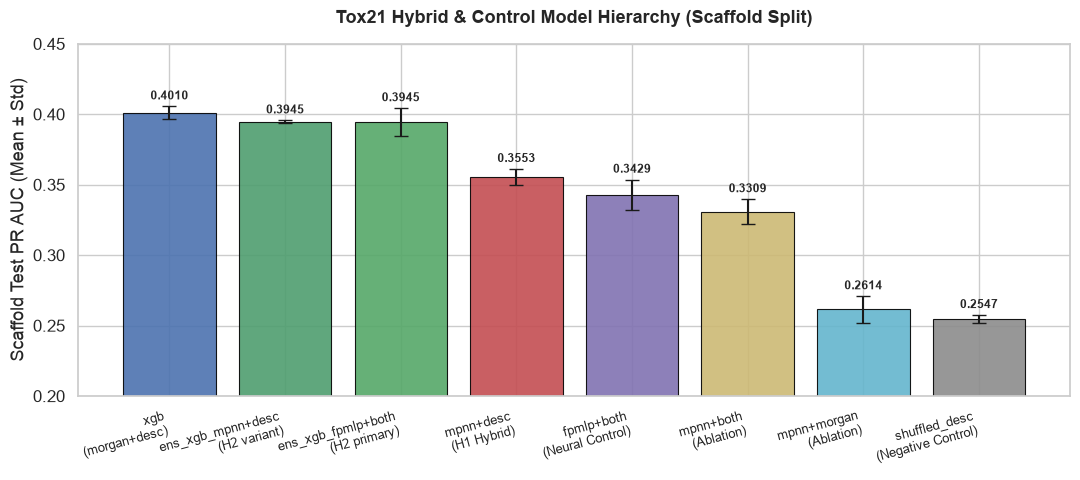

Saved figure to /Users/ranajeetroy/Desktop/Molecular-Toxicity-Prediction/tox21-phase1/report_phase2/figures/hybrid_hierarchy_scaffold.png


In [10]:
fig_dir = ROOT / "report_phase2/figures"
fig_dir.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", font_scale=1.1)

# Every bar is computed from the committed CSVs - no hard-coded numbers (handbook N-1).
def scaffold_pr(frame, model, fs, tag=None):
    d = frame[(frame.model == model) & (frame.feature_set == fs) & (frame.split == "scaffold")]
    if tag is not None:
        d = d[d.tag == tag]
    per_seed = d.groupby("seed")["pr_auc"].mean()
    return per_seed.mean(), per_seed.std(ddof=1)

bar_spec = [
    ("xgb\n(morgan+desc)",            df,  "xgb",             "morgan+desc",     None,            "#4C72B0"),
    ("ens_xgb_fpmlp+both\n(H2 primary)", df, "ens_xgb_fpmlp+both", "morgan+desc+both", None,        "#55A868"),
    ("ens_xgb_mpnn+desc\n(H2 variant)",  df, "ens_xgb_mpnn+desc",  "morgan+desc+graph+desc", None,  "#4F9E6F"),
    ("mpnn+desc\n(H1 Hybrid)",        df,  "mpnn+desc",       "graph+desc",      None,            "#C44E52"),
    ("fpmlp+both\n(Neural Control)",  df,  "fpmlp+both",      "both",            None,            "#8172B2"),
    ("mpnn+both\n(Ablation)",         abl, "mpnn+both",       "graph+both",      "both",          "#CCB974"),
    ("mpnn+morgan\n(Ablation)",       abl, "mpnn+morgan",     "graph+morgan",    "morgan",        "#64B5CD"),
    ("shuffled_desc\n(Negative Control)", abl, "mpnn+desc",   "graph+desc",      "shuffled_desc", "#8C8C8C"),
]

labels, means, stds, colors = [], [], [], []
for lab, frame, model, fs, tag, colour in bar_spec:
    m, sd = scaffold_pr(frame, model, fs, tag)
    labels.append(lab); means.append(m); stds.append(sd); colors.append(colour)

order = np.argsort(means)[::-1]
labels = [labels[i] for i in order]; means = [means[i] for i in order]
stds = [stds[i] for i in order];     colors = [colors[i] for i in order]

fig, ax = plt.subplots(figsize=(11, 5))
x_pos = np.arange(len(labels))
ax.bar(x_pos, means, yerr=stds, capsize=5, color=colors, alpha=0.9, edgecolor="black", linewidth=0.8)
ax.set_ylabel("Scaffold Test PR AUC (Mean ± Std)")
ax.set_title("Tox21 Hybrid & Control Model Hierarchy (Scaffold Split)", pad=15, fontweight="bold")
ax.set_xticks(x_pos)
ax.set_xticklabels(labels, rotation=15, ha="right", fontsize=9)
ax.set_ylim(0.2, 0.45)
for i, (m, sd) in enumerate(zip(means, stds)):
    ax.text(i, m + sd + 0.005, f"{m:.4f}", ha="center", fontsize=8.5, fontweight="bold")

plt.tight_layout()
plt.savefig(fig_dir / "hybrid_hierarchy_scaffold.png", dpi=300)
plt.savefig(fig_dir / "hybrid_hierarchy_scaffold.pdf")
plt.show()
print(f"Saved figure to {fig_dir / 'hybrid_hierarchy_scaffold.png'}")


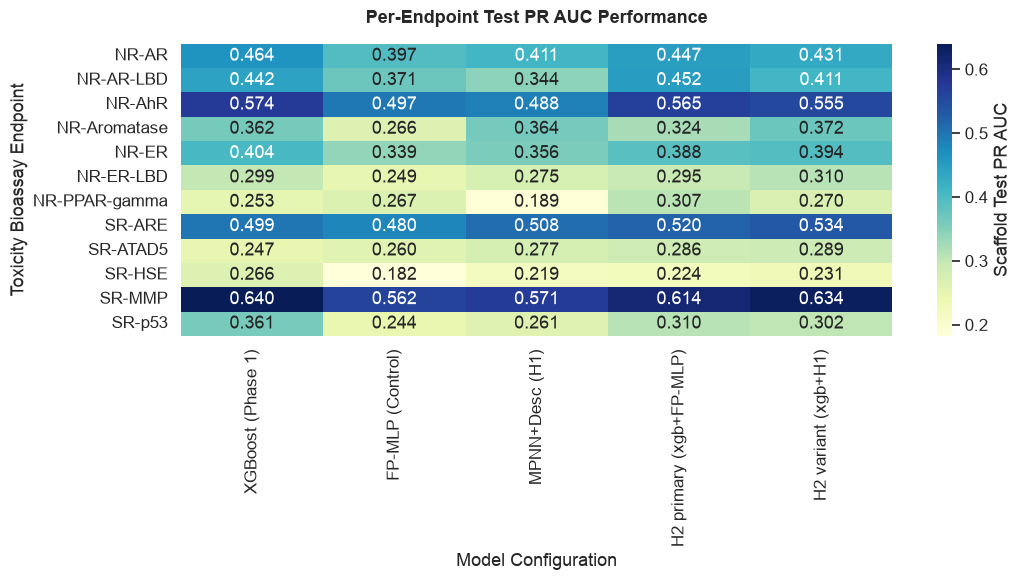

Saved heatmap to /Users/ranajeetroy/Desktop/Molecular-Toxicity-Prediction/tox21-phase1/report_phase2/figures/endpoint_pr_heatmap.png


In [11]:
# Plot 2: Per-endpoint comparison heatmap
plt.figure(figsize=(11, 6))
heatmap_data = endpoint_pr_filtered.copy()
heatmap_data.columns = ["XGBoost (Phase 1)", "FP-MLP (Control)", "MPNN+Desc (H1)",
                        "H2 primary (xgb+FP-MLP)", "H2 variant (xgb+H1)"]

sns.heatmap(heatmap_data, annot=True, fmt=".3f", cmap="YlGnBu", cbar_kws={'label': 'Scaffold Test PR AUC'})
plt.title("Per-Endpoint Test PR AUC Performance", pad=15, fontweight="bold")
plt.xlabel("Model Configuration")
plt.ylabel("Toxicity Bioassay Endpoint")
plt.tight_layout()
plt.savefig(fig_dir / "endpoint_pr_heatmap.png", dpi=300)
plt.savefig(fig_dir / "endpoint_pr_heatmap.pdf")
plt.show()
print(f"Saved heatmap to {fig_dir / 'endpoint_pr_heatmap.png'}")


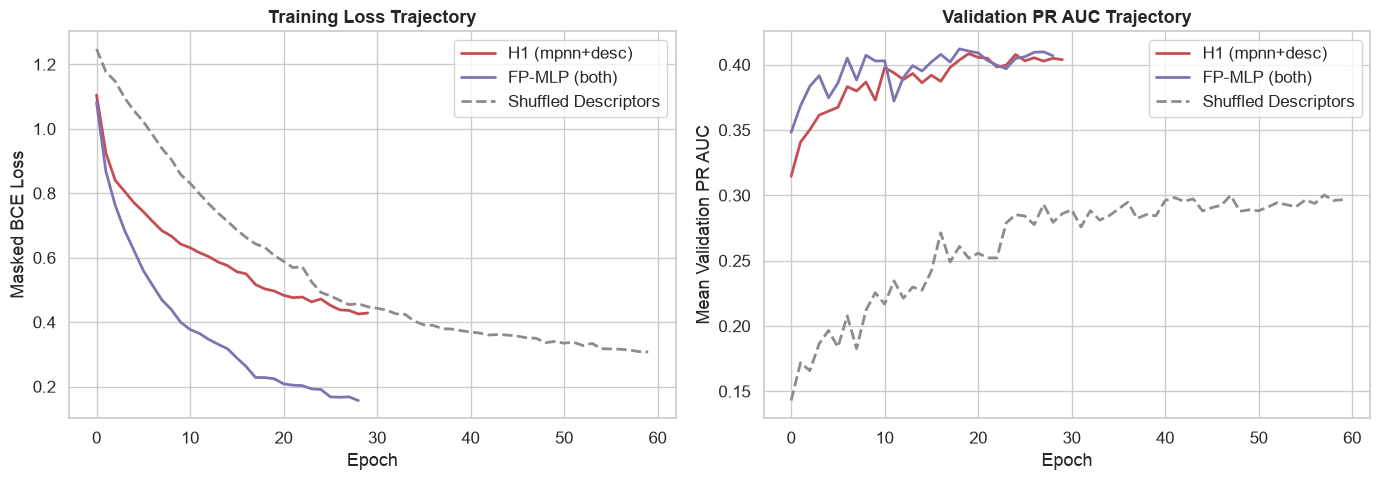

Saved learning curves to /Users/ranajeetroy/Desktop/Molecular-Toxicity-Prediction/tox21-phase1/report_phase2/figures/hybrid_learning_curves.png


In [12]:
# Plot 3: Learning curves comparison
curves_dir = RESULTS / "curves"
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Load curves for scaffold seed 0
with open(curves_dir / "mpnn+desc_graph+desc_scaffold_seed0_final.json") as f:
    c_h1 = json.load(f)
with open(curves_dir / "fpmlp+both_both_scaffold_seed0_final.json") as f:
    c_mlp = json.load(f)
with open(curves_dir / "mpnn+desc_graph+desc_scaffold_seed0_shuffled_desc.json") as f:
    c_shuf = json.load(f)

# Train loss
ax1.plot([x["epoch"] for x in c_h1], [x["train_loss"] for x in c_h1], label="H1 (mpnn+desc)", color="#C44E52", lw=2)
ax1.plot([x["epoch"] for x in c_mlp], [x["train_loss"] for x in c_mlp], label="FP-MLP (both)", color="#8172B2", lw=2)
ax1.plot([x["epoch"] for x in c_shuf], [x["train_loss"] for x in c_shuf], label="Shuffled Descriptors", color="#8C8C8C", lw=2, linestyle="--")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Masked BCE Loss")
ax1.set_title("Training Loss Trajectory", fontweight="bold")
ax1.legend()

# Validation PR AUC
ax2.plot([x["epoch"] for x in c_h1], [x["val_pr"] for x in c_h1], label="H1 (mpnn+desc)", color="#C44E52", lw=2)
ax2.plot([x["epoch"] for x in c_mlp], [x["val_pr"] for x in c_mlp], label="FP-MLP (both)", color="#8172B2", lw=2)
ax2.plot([x["epoch"] for x in c_shuf], [x["val_pr"] for x in c_shuf], label="Shuffled Descriptors", color="#8C8C8C", lw=2, linestyle="--")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Mean Validation PR AUC")
ax2.set_title("Validation PR AUC Trajectory", fontweight="bold")
ax2.legend()

plt.tight_layout()
plt.savefig(fig_dir / "hybrid_learning_curves.png", dpi=300)
plt.savefig(fig_dir / "hybrid_learning_curves.pdf")
plt.show()
print(f"Saved learning curves to {fig_dir / 'hybrid_learning_curves.png'}")
